In [17]:
# Листинг 1 — Создание окружения и установка зависимостей
# !python -m venv .venv
# !.venv\Scripts\activate
# !python -m pip install "numpy>=1.26" "pandas>=2.1" "matplotlib>=3.8" "seaborn>=0.13" "scikit-learn>=1.4,<2"

In [18]:
# Листинг 2 — Базовые импорты, версии и единый seed

# Стандартная библиотека используется для времени и путей к файлам.
from pathlib import Path
from statistics import median
from time import perf_counter

# Научный стек: таблицы, массивы, графики и клонирование моделей.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone

# Компоненты scikit-learn для preprocessing, моделей и метрик.
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

# Фиксируем один seed для всех случайных разбиений эксперимента.
VARIANT = 4
RANDOM_STATE = 1000 + VARIANT
np.random.seed(RANDOM_STATE)

# Печатаем версии: они должны быть указаны в отчёте.
import sklearn
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

NumPy: 2.5.3
pandas: 3.0.6
scikit-learn: 1.9.1


In [19]:
# Листинг 3 — Функция загрузки варианта из локального архива
# Каталог должен находиться рядом с текущим Jupyter Notebook.
DATA_DIR = Path("ML_Lab3_Datasets")

def load_local_variant(variant, data_dir=DATA_DIR):
    """Возвращает признаки, целевую переменную и строку manifest."""
    # dtype=str сохраняет идентификаторы и имена столбцов без преобразований.
    manifest = pd.read_csv(data_dir / "manifest.csv", dtype=str)
    row = manifest.loc[manifest["variant"] == str(variant)]
    if row.empty:
        raise ValueError(f"Вариант {variant} отсутствует в manifest.csv")
    card = row.iloc[0]

    # Стандартные обозначения пропусков преобразуем в np.nan.
    frame = pd.read_csv(
        data_dir / card["file_name"],
        na_values=["?", "NA", "null", ""],
    )
    target_column = card["target_column"]
    if target_column not in frame.columns:
        raise KeyError(f"Нет целевого столбца {target_column!r}")

    # Объекты без целевой метки нельзя использовать в обучении с учителем.
    labeled = frame[target_column].notna()
    removed = int((~labeled).sum())
    if removed:
        print(f"Исключено объектов без метки: {removed}")
    X = frame.loc[labeled].drop(columns=target_column).reset_index(drop=True)
    y = frame.loc[labeled, target_column].astype(str).reset_index(drop=True)
    return X, y, card

X, y, card = load_local_variant(VARIANT)
y = y.astype(int)   # метки 1…10 — числа, классы идут в естественном порядке
print("Файл:", DATA_DIR / card["file_name"])
print("Размер X:", X.shape)
print("Целевой столбец:", card["target_column"])

Файл: ML_Lab3_Datasets\variant_04.csv
Размер X: (2000, 64)
Целевой столбец: class


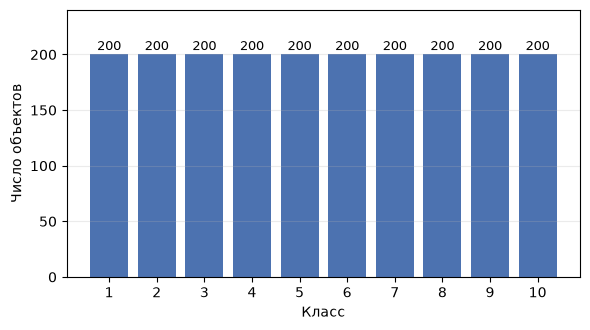

In [20]:
# Рисунок 1 — распределение объектов по классам.
IMAGES_DIR = Path("images")
IMAGES_DIR.mkdir(exist_ok=True)

class_counts = y.value_counts().sort_index()

plt.figure(figsize=(6, 3.4))
plt.bar(class_counts.index.astype(str), class_counts.values, color="#4c72b0")
for position, count in enumerate(class_counts.values):
    plt.text(position, count + 4, str(count), ha="center", fontsize=9)
plt.xlabel("Класс")
plt.ylabel("Число объектов")
plt.ylim(0, class_counts.max() * 1.2)
plt.grid(alpha=0.25, axis="y")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "class_dist.png", dpi=200)
plt.show()

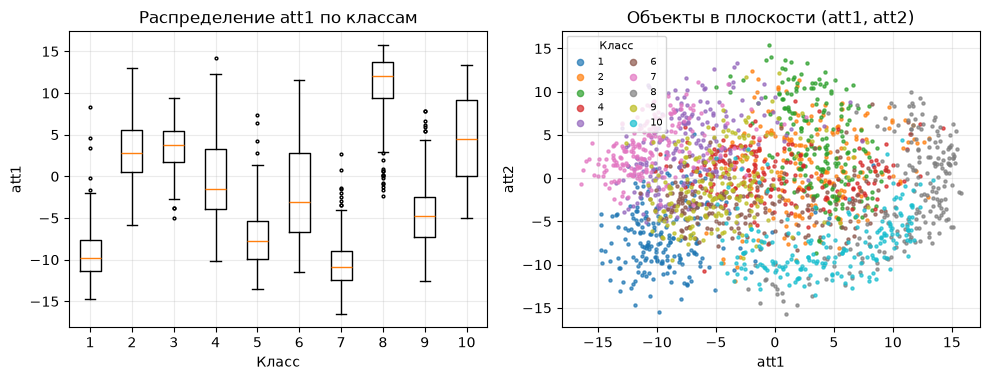

In [21]:

class_labels = sorted(y.unique())
colors = plt.get_cmap("tab10")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9))

# Левый график: boxplot признака att1 по классам.
axes[0].boxplot(
    [X.loc[y == label, "att1"] for label in class_labels],
    flierprops=dict(markersize=2),
)
axes[0].set_xticklabels([str(label) for label in class_labels])
axes[0].set_xlabel("Класс")
axes[0].set_ylabel("att1")
axes[0].set_title("Распределение att1 по классам")
axes[0].grid(alpha=0.25)

# Правый график: диаграмма рассеяния в плоскости (att1, att2).
for index, label in enumerate(class_labels):
    mask = y == label
    axes[1].scatter(
        X.loc[mask, "att1"], X.loc[mask, "att2"],
        s=5, color=colors(index), alpha=0.7, label=str(label),
    )
axes[1].set_xlabel("att1")
axes[1].set_ylabel("att2")
axes[1].set_title("Объекты в плоскости (att1, att2)")
axes[1].grid(alpha=0.25)
axes[1].legend(title="Класс", ncol=2, fontsize=7, title_fontsize=8, markerscale=2)

plt.tight_layout()
plt.savefig(IMAGES_DIR / "features.png", dpi=200)
plt.show()


In [22]:
# Таблица 3 — Карточка исходного набора
print("Вариант и data_id:", VARIANT, "/", card["data_id"], card["dataset_name"])
print("Размер:", X.shape[0], "объектов,", X.shape[1], "исходных признаков")
print("Целевая переменная:", card["target_column"], "| классов:", y.nunique())
print("Баланс классов:", class_counts.to_dict())
print("Типы признаков:", X.dtypes.value_counts().to_dict())
print("Пропуски:", int(X.isna().sum().sum()))
print("Полных дубликатов:", int(pd.concat([X, y.rename("class")], axis=1).duplicated().sum()), "(оставлены)")
print("Столбцов-идентификаторов:", sum(X[c].nunique() == len(X) for c in X.columns))

Вариант и data_id: 4 / 16 mfeat-karhunen
Размер: 2000 объектов, 64 исходных признаков
Целевая переменная: class | классов: 10
Баланс классов: {1: 200, 2: 200, 3: 200, 4: 200, 5: 200, 6: 200, 7: 200, 8: 200, 9: 200, 10: 200}
Типы признаков: {dtype('float64'): 64}
Пропуски: 0
Полных дубликатов: 6 (оставлены)
Столбцов-идентификаторов: 0


In [23]:
# Листинг 10 — Таблица метрик классификации
def classification_metrics(y_true, y_pred):
    """Возвращает три взаимодополняющие метрики классификации."""
    # Accuracy удобна для общего понимания доли правильных ответов.
    accuracy = accuracy_score(y_true, y_pred)

    # Balanced accuracy одинаково учитывает полноту каждого класса.
    balanced = balanced_accuracy_score(y_true, y_pred)

    # Macro-F1 одинаково взвешивает классы и служит основным критерием.
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    return {
        "accuracy": accuracy,
        "balanced_accuracy": balanced,
        "macro_f1": macro_f1,
    }

In [24]:
# Листинг 6 — Фиксация train, validation, test, preprocessing и baseline
# Сначала откладываем закрытый test: он не участвует в выборе моделей.
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

# Из оставшихся 80 % выделяем validation: итоговая пропорция 60/20/20.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,
    stratify=y_train_full,
    random_state=RANDOM_STATE,
)

# Сбрасываем индексы, чтобы таблицы ошибок не выравнивались по старым индексам.
X_train = X_train.reset_index(drop=True)
X_val = X_val.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_val = y_val.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

def make_preprocessor(X_train):
    """Создаёт преобразователь, но не обучает его заранее."""
    # Типы столбцов определяем только по структуре train.
    numeric = X_train.select_dtypes(include="number").columns.tolist()
    categorical = [column for column in X_train.columns
                   if column not in numeric]
    transformers = []

    # Числа: медианная импутация, затем стандартизация расстояний.
    if numeric:
        numeric_pipeline = Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ])
        transformers.append(("numeric", numeric_pipeline, numeric))

    # Категории: частая категория и плотное one-hot кодирование.
    if categorical:
        categorical_pipeline = Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            )),
        ])
        transformers.append(("categorical", categorical_pipeline, categorical))

    # sparse_threshold=0 гарантирует плотный массив для всех рассматриваемых моделей.
    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        sparse_threshold=0.0,
    )

preprocessor = make_preprocessor(X_train)

# Baseline всегда предсказывает самый частый класс обучающей выборки.
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_prediction = baseline.predict(X_val)

# Macro-F1 показывает, насколько модель превосходит тривиальное правило.
baseline_metrics = classification_metrics(y_val, baseline_prediction)
print("Размеры:", len(X_train), len(X_val), len(X_test))
print("Baseline validation:", baseline_metrics)

Размеры: 1200 400 400
Baseline validation: {'accuracy': 0.1, 'balanced_accuracy': 0.1, 'macro_f1': 0.01818181818181818}


In [25]:
# Листинг 7 — kNN-классификатор средствами NumPy
def manual_knn_predict(
    X_train,
    y_train,
    X_query,
    *,
    k=5,
    weighted=False,
):
    """Предсказывает класс каждого объекта из X_query."""
    # Явно преобразуем входы в массивы и проверяем допустимость k.
    X_train = np.asarray(X_train, dtype=float)
    X_query = np.asarray(X_query, dtype=float)
    y_train = np.asarray(y_train)
    if not 1 <= k <= len(X_train):
        raise ValueError("k должно лежать между 1 и размером train")

    predictions = []
    for query in X_query:
        # Евклидово расстояние вычисляется до каждого объекта train.
        distances = np.sqrt(np.sum((X_train - query) ** 2, axis=1))
        order = np.argsort(distances, kind="mergesort")[:k]
        neighbor_labels = y_train[order]
        neighbor_distances = distances[order]

        # При точном совпадении голосуют только соседи с нулевой дистанцией.
        if weighted and np.any(neighbor_distances <= 1e-12):
            weights = (neighbor_distances <= 1e-12).astype(float)
        # В остальных случаях взвешенный режим усиливает близких соседей.
        elif weighted:
            weights = 1.0 / neighbor_distances
        else:
            weights = np.ones(k, dtype=float)

        # Суммируем голоса отдельно для каждого встреченного класса.
        scores = {}
        for label, weight in zip(neighbor_labels, weights):
            scores[label] = scores.get(label, 0.0) + float(weight)

        # При равенстве голосов выбираем минимальную метку, как sklearn.
        predictions.append(max(sorted(scores), key=scores.get))
    return np.asarray(predictions)

In [26]:
# Листинг 8 — Сопоставление ручного kNN с KNeighborsClassifier
# Отдельная копия preprocessing обучается исключительно для проверки kNN.
manual_preprocessor = clone(preprocessor)
X_train_manual = manual_preprocessor.fit_transform(X_train)
X_val_manual = manual_preprocessor.transform(X_val)

# Проверяем первые 50 объектов validation, но сохраняем весь train.
check_size = min(50, len(X_val_manual))
manual_prediction = manual_knn_predict(
    X_train_manual,
    y_train.to_numpy(),
    X_val_manual[:check_size],
    k=5,
    weighted=True,
)

# Готовая модель получает те же данные и те же параметры.
library_knn = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    p=2,
)
library_knn.fit(X_train_manual, y_train)
library_prediction = library_knn.predict(X_val_manual[:check_size])

# Совпадение прогнозов подтверждает корректность базовой реализации.
agreement = np.mean(manual_prediction == library_prediction)
manual_f1 = f1_score(y_val[:check_size], manual_prediction, average="macro")
print("Доля совпавших прогнозов:", round(agreement, 4))
print("Ручной kNN macro-F1:", round(manual_f1, 4))

Доля совпавших прогнозов: 1.0
Ручной kNN macro-F1: 0.96


In [27]:
# Листинг 9 — Эксперимент с искусственно искажённым масштабом
# Умножаем второй признак на 100, не изменяя информацию в данных.
X_train_distorted = X_train.copy()
X_val_distorted = X_val.copy()
X_train_distorted.iloc[:, 1] *= 100.0
X_val_distorted.iloc[:, 1] *= 100.0

# Копия preprocessing без стандартизации: импутация сохраняется.
preprocessor_without_scaling = clone(preprocessor).set_params(
    numeric__scale="passthrough",
)

# Модель без стандартизации почти игнорирует остальные признаки.
knn_without_scaling = Pipeline([
    ("preprocess", preprocessor_without_scaling),
    ("model", KNeighborsClassifier(
        n_neighbors=11,
        weights="distance",
    )),
])
knn_without_scaling.fit(X_train_distorted, y_train)
pred_without = knn_without_scaling.predict(X_val_distorted)

# Pipeline обучает StandardScaler только на train, затем применяет kNN.
knn_with_scaling = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", KNeighborsClassifier(
        n_neighbors=11,
        weights="distance",
    )),
])
knn_with_scaling.fit(X_train_distorted, y_train)
pred_with = knn_with_scaling.predict(X_val_distorted)

# Сравниваем модели одной метрикой и на одном validation.
print("Без scaling:", f1_score(y_val, pred_without, average="macro"))
print("Со scaling:", f1_score(y_val, pred_with, average="macro"))

Без scaling: 0.5899091709357019
Со scaling: 0.9473806753610884


In [28]:
# Таблица 4 — Ближайшие соседи и macro-F1 до и после искажения масштаба
# Те же kNN, обученные на исходном (неискажённом) train.
knn_plain_without = clone(knn_without_scaling).fit(X_train, y_train)
knn_plain_with = clone(knn_with_scaling).fit(X_train, y_train)

def neighbors(model, X):
    """Индексы соседей первых check_size объектов validation."""
    Z = model[:-1].transform(X.iloc[:check_size])
    return model.named_steps["model"].kneighbors(Z, return_distance=False)

def common_share(a, b):
    """Средняя доля общих соседей двух наборов."""
    return np.mean([len(set(r) & set(s)) / len(r) for r, s in zip(a, b)])

# Эталон — исходные данные со стандартизацией.
reference = neighbors(knn_plain_with, X_val)
scaling_table = pd.DataFrame([
    {"данные": "исходные", "scaling": "да",
     "macro_f1": f1_score(y_val, knn_plain_with.predict(X_val), average="macro"),
     "общих соседей": 1.0},
    {"данные": "исходные", "scaling": "нет",
     "macro_f1": f1_score(y_val, knn_plain_without.predict(X_val), average="macro"),
     "общих соседей": common_share(reference, neighbors(knn_plain_without, X_val))},
    {"данные": "att2 x100", "scaling": "да",
     "macro_f1": f1_score(y_val, pred_with, average="macro"),
     "общих соседей": common_share(reference, neighbors(knn_with_scaling, X_val_distorted))},
    {"данные": "att2 x100", "scaling": "нет",
     "macro_f1": f1_score(y_val, pred_without, average="macro"),
     "общих соседей": common_share(reference, neighbors(knn_without_scaling, X_val_distorted))},
])
print(scaling_table.round(4))

      данные scaling  macro_f1  общих соседей
0   исходные      да    0.9474         1.0000
1   исходные     нет    0.9726         0.7255
2  att2 x100      да    0.9474         1.0000
3  att2 x100     нет    0.5899         0.0618


In [29]:
# Листинг 11 — Кросс-валидация k, weights и p
# Одинаковые фолды используются для всех конфигураций.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# Preprocessing находится внутри Pipeline и переобучается на каждом фолде.
knn_pipeline = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", KNeighborsClassifier()),
])

# Сетка проверяет размер окрестности, голоса и две метрики Минковского.
knn_grid = {
    "model__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
}
knn_search = GridSearchCV(
    knn_pipeline,
    knn_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
)
knn_search.fit(X_train, y_train)

# Best score относится к CV на train, а не к validation или test.
print("Лучшие параметры:", knn_search.best_params_)
print("Средний CV macro-F1:", round(knn_search.best_score_, 4))
print("Std CV macro-F1:", round(knn_search.cv_results_["std_test_score"][knn_search.best_index_], 4))
knn_val_prediction = knn_search.predict(X_val)
print(classification_metrics(y_val, knn_val_prediction))

# Таблица cv_results_ нужна для графика качества в зависимости от k.
knn_cv_results = pd.DataFrame(knn_search.cv_results_)
columns = [
    "param_model__n_neighbors",
    "param_model__weights",
    "param_model__p",
    "mean_test_score",
    "std_test_score",
]
print(knn_cv_results[columns].sort_values("mean_test_score", ascending=False).head(10))

Лучшие параметры: {'model__n_neighbors': 1, 'model__p': 2, 'model__weights': 'uniform'}
Средний CV macro-F1: 0.9463
Std CV macro-F1: 0.0129
{'accuracy': 0.955, 'balanced_accuracy': 0.9549999999999998, 'macro_f1': 0.9547848355787739}
    param_model__n_neighbors param_model__weights  param_model__p  \
3                          1             distance               2   
2                          1              uniform               2   
7                          3             distance               2   
9                          5             distance               1   
11                         5             distance               2   
5                          3             distance               1   
0                          1              uniform               1   
1                          1             distance               1   
6                          3              uniform               2   
15                         7             distance               2   

    mea

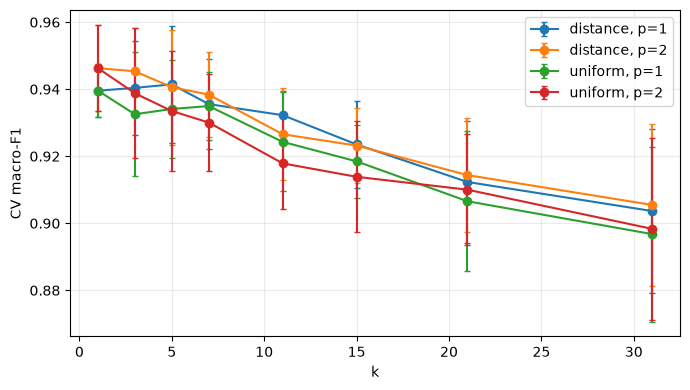

In [30]:
# Рисунок 3 — CV macro-F1 kNN в зависимости от k, weights и p
plt.figure(figsize=(7, 4))
for (weights, p), part in knn_cv_results.groupby(["param_model__weights", "param_model__p"]):
    part = part.sort_values("param_model__n_neighbors")
    plt.errorbar(
        part["param_model__n_neighbors"].astype(int), part["mean_test_score"],
        yerr=part["std_test_score"], marker="o", capsize=2,
        label=f"{weights}, p={p}",
    )
plt.xlabel("k")
plt.ylabel("CV macro-F1")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "knn_cv.png", dpi=200)
plt.show()

In [31]:
# Листинг 12 — Два семейства SVM по одинаковым фолдам
# Дисбаланс оцениваем только по train; при отношении >= 2 проверяем class_weight.
class_counts_train = y_train.value_counts()
imbalance_ratio = class_counts_train.max() / class_counts_train.min()
weight_options = [None, "balanced"] if imbalance_ratio >= 2 else [None]
print("Отношение max/min частот классов в train:", round(imbalance_ratio, 2))

# Линейный SVM настраивается только по параметру C.
linear_svm = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", SVC(kernel="linear")),
])
linear_search = GridSearchCV(
    linear_svm,
    {
        "model__C": [0.01, 0.1, 1.0, 10.0, 100.0],
        "model__class_weight": weight_options,
    },
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
)
linear_search.fit(X_train, y_train)

# Для RBF-SVM параметры C и gamma подбираются совместно.
rbf_svm = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("model", SVC(kernel="rbf")),
])
rbf_search = GridSearchCV(
    rbf_svm,
    {
        "model__C": [0.1, 1.0, 10.0, 100.0],
        "model__gamma": ["scale", 0.01, 0.1, 1.0],
        "model__class_weight": weight_options,
    },
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
)
rbf_search.fit(X_train, y_train)

# Validation остаётся независимым от внутренней кросс-валидации.
for name, search in {
    "linear SVM": linear_search,
    "RBF SVM": rbf_search,
}.items():
    prediction = search.predict(X_val)
    support_count = int(search.best_estimator_.named_steps["model"].n_support_.sum())
    print(name, search.best_params_)
    print("CV macro-F1: %.4f ± %.4f" % (
        search.cv_results_["mean_test_score"][search.best_index_],
        search.cv_results_["std_test_score"][search.best_index_]))
    print(classification_metrics(y_val, prediction))
    print("Опорных векторов:", support_count)
    print("Доля опорных векторов:", support_count / len(X_train))

Отношение max/min частот классов в train: 1.0
linear SVM {'model__C': 0.01, 'model__class_weight': None}
CV macro-F1: 0.9559 ± 0.0172
{'accuracy': 0.96, 'balanced_accuracy': 0.96, 'macro_f1': 0.9600897786260756}
Опорных векторов: 718
Доля опорных векторов: 0.5983333333333334
RBF SVM {'model__C': 10.0, 'model__class_weight': None, 'model__gamma': 0.01}
CV macro-F1: 0.9734 ± 0.0132
{'accuracy': 0.9725, 'balanced_accuracy': 0.9724999999999999, 'macro_f1': 0.9724601170386906}
Опорных векторов: 797
Доля опорных векторов: 0.6641666666666667


In [32]:
# Таблица 5 — Влияние C (linear) и C × gamma (RBF) на CV macro-F1
linear_cv_results = pd.DataFrame(linear_search.cv_results_)
print(linear_cv_results[["param_model__C", "mean_test_score", "std_test_score"]])

rbf_cv_results = pd.DataFrame(rbf_search.cv_results_)
print(rbf_cv_results.pivot_table(
    index="param_model__C", columns="param_model__gamma",
    values="mean_test_score", aggfunc="max",
).round(4))

   param_model__C  mean_test_score  std_test_score
0            0.01         0.955911        0.017156
1            0.10         0.950932        0.008065
2            1.00         0.944155        0.009973
3           10.00         0.944155        0.009973
4          100.00         0.944155        0.009973
param_model__gamma    0.01     0.1     1.0   scale
param_model__C                                    
0.1                 0.9162  0.3510  0.0432  0.9147
1.0                 0.9684  0.8082  0.0791  0.9693
10.0                0.9734  0.8191  0.0909  0.9709
100.0               0.9734  0.8191  0.0909  0.9709


In [33]:
# Листинг 13 — Измерение fit, predict и размера опорного множества
def measure_classifier(name, estimator, X_train, y_train, X_val, y_val, repeats=5):
    """Переобучает модель repeats раз и возвращает медианы времени."""
    fit_times, predict_times = [], []
    for _ in range(repeats):
        # clone создаёт чистую модель с теми же выбранными параметрами.
        model = clone(estimator)
        start = perf_counter()
        model.fit(X_train, y_train)
        fit_times.append(perf_counter() - start)

        start = perf_counter()
        prediction = model.predict(X_val)
        predict_times.append(perf_counter() - start)

    # Время приводим к 1000 объектам для удобства сравнения.
    fit_ms = 1000.0 * median(fit_times)
    predict_ms_1000 = 1_000_000.0 * median(predict_times) / len(X_val)

    # Для SVC считаем опорные векторы, для kNN — сохранённый train.
    inner_model = model.named_steps["model"]
    if hasattr(inner_model, "n_support_"):
        stored_objects = int(inner_model.n_support_.sum())
    else:
        stored_objects = len(X_train)

    metrics = classification_metrics(y_val, prediction)
    return {
        "model": name,
        **metrics,
        "fit_ms": fit_ms,
        "predict_ms_per_1000": predict_ms_1000,
        "stored_objects": stored_objects,
        "stored_share": stored_objects / len(X_train),
    }

# Все семейства оцениваются на одном и том же validation.
candidates = {
    "kNN": knn_search.best_estimator_,
    "linear SVM": linear_search.best_estimator_,
    "RBF SVM": rbf_search.best_estimator_,
}
comparison = pd.DataFrame([
    measure_classifier(name, model, X_train, y_train, X_val, y_val)
    for name, model in candidates.items()
]).sort_values("macro_f1", ascending=False)
print(comparison.round(4))

        model  accuracy  balanced_accuracy  macro_f1   fit_ms  \
2     RBF SVM    0.9725             0.9725    0.9725  41.3131   
1  linear SVM    0.9600             0.9600    0.9601  30.8861   
0         kNN    0.9550             0.9550    0.9548  10.3504   

   predict_ms_per_1000  stored_objects  stored_share  
2              55.3435             797        0.6642  
1              24.3727             718        0.5983  
0              22.1550            1200        1.0000  


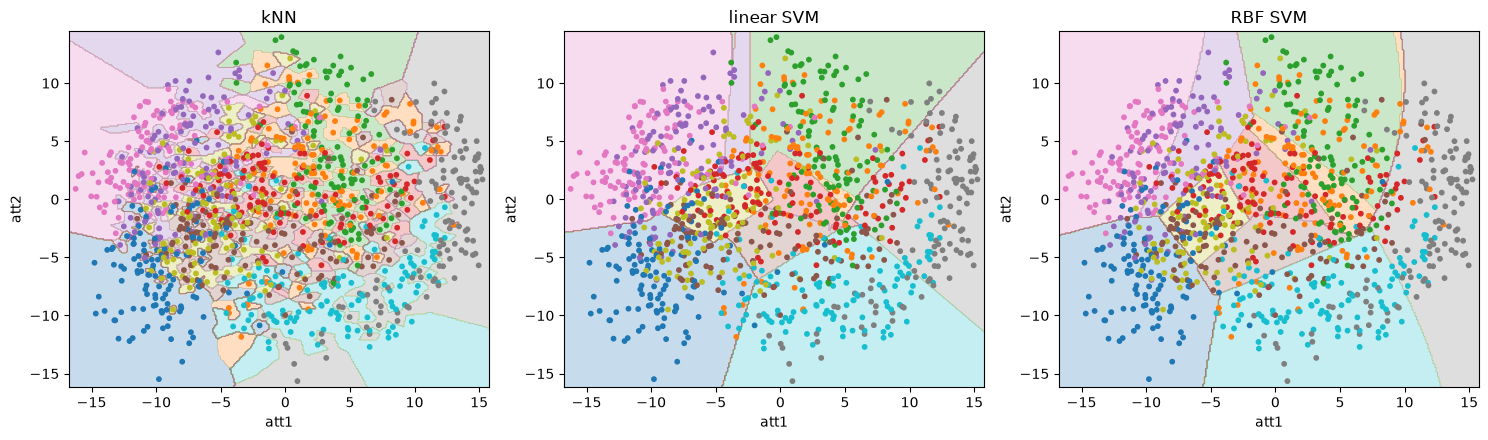

In [34]:
# Листинг 14 — Решающие области kNN, linear SVM и RBF SVM
def plot_decision_region(ax, estimator, X, y, title):
    """Обучает модель и отображает её решение на двумерной сетке."""
    # Сетку строим в исходном пространстве; scaling выполняет Pipeline.
    x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x2_min, x2_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x1_min, x1_max, 300),
        np.linspace(x2_min, x2_max, 300),
    )

    # Для честной демонстрации модель обучается только на train.
    model = clone(estimator)
    model.fit(X, y)
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)

    # Фон показывает классы модели, точки — реальные train-объекты.
    levels = np.arange(-0.5, len(np.unique(y)) + 0.5)
    ax.contourf(xx, yy, zz, levels=levels, alpha=0.25, cmap="tab10", vmin=-0.5, vmax=9.5)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="tab10", vmin=-0.5, vmax=9.5, s=10)
    ax.set_title(title)
    ax.set_xlabel("att1")
    ax.set_ylabel("att2")

# Области строятся на двух исходных признаках att1 и att2 отдельными 2D-моделями
# с гиперпараметрами лучших моделей; test не используется.
X_train_2d = X_train[["att1", "att2"]].to_numpy()
y_train_codes = y_train.to_numpy() - 1
visual_models = {
    name: Pipeline([
        ("scale", StandardScaler()),
        ("model", clone(model.named_steps["model"])),
    ])
    for name, model in candidates.items()
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, estimator) in zip(axes, visual_models.items()):
    plot_decision_region(ax, estimator, X_train_2d, y_train_codes, name)
plt.tight_layout()
plt.savefig(IMAGES_DIR / "decision_regions.png", dpi=200)
plt.show()

In [35]:
# Листинг 15 — Выбор по validation, переобучение и однократный test
# Сравниваем уже настроенные семейства только по validation macro-F1.
validation_scores = {}
for name, estimator in candidates.items():
    prediction = estimator.predict(X_val)
    validation_scores[name] = f1_score(
        y_val,
        prediction,
        average="macro",
    )

# После этой строки семейство и все гиперпараметры считаются зафиксированными.
# При равенстве macro-F1 выбирается модель с меньшим временем predict.
predict_ms = comparison.set_index("model")["predict_ms_per_1000"]
best_name = max(
    validation_scores,
    key=lambda name: (round(validation_scores[name], 4), -predict_ms[name]),
)
best_pipeline = candidates[best_name]
print("Выбрана модель:", best_name)
print("Validation scores:", validation_scores)

# Объединяем train и validation только после завершения выбора.
X_train_val = pd.concat([X_train, X_val], ignore_index=True)
y_train_val = pd.concat([y_train, y_val], ignore_index=True)
final_model = clone(best_pipeline)
final_model.fit(X_train_val, y_train_val)

# Test открывается ровно один раз для итоговой несмещённой оценки.
test_prediction = final_model.predict(X_test)
test_metrics = classification_metrics(y_test, test_prediction)
print("Test metrics:", test_metrics)
print(classification_report(y_test, test_prediction, digits=3))

Выбрана модель: RBF SVM
Validation scores: {'kNN': 0.9547848355787739, 'linear SVM': 0.9600897786260756, 'RBF SVM': 0.9724601170386906}
Test metrics: {'accuracy': 0.99, 'balanced_accuracy': 0.99, 'macro_f1': 0.9898998017141476}
              precision    recall  f1-score   support

           1      0.976     1.000     0.988        40
           2      0.976     1.000     0.988        40
           3      1.000     1.000     1.000        40
           4      1.000     0.925     0.961        40
           5      1.000     0.975     0.987        40
           6      1.000     1.000     1.000        40
           7      1.000     1.000     1.000        40
           8      0.976     1.000     0.988        40
           9      1.000     1.000     1.000        40
          10      0.976     1.000     0.988        40

    accuracy                          0.990       400
   macro avg      0.990     0.990     0.990       400
weighted avg      0.990     0.990     0.990       400



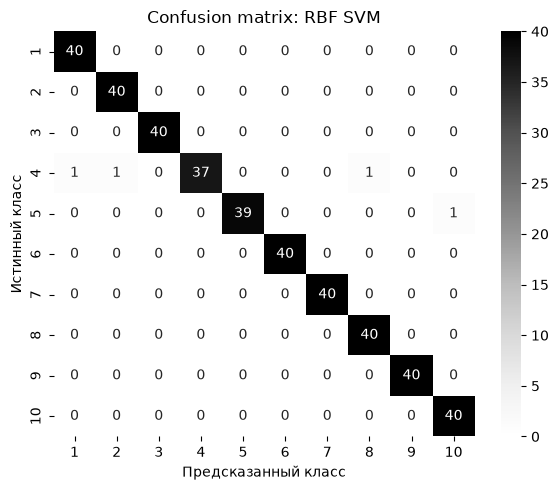

Число ошибок: 4
          att1       att2      att3      att4      att5  true  predicted
231  -6.035366 -10.678077  1.473566  6.008083 -5.200163     4          1
303   5.363024   5.736277  2.384048  9.232138  5.200172     4          2
369  14.225326   5.820617  3.543279  2.309732  0.874343     4          8
385  -3.185716  -5.169368 -4.394968  7.903034  5.289021     5         10


In [36]:
# Листинг 16 — Матрица ошибок и таблица ошибочных объектов
# Фиксированный порядок классов делает подписи матрицы однозначными.
labels = np.unique(y_test)
matrix = confusion_matrix(y_test, test_prediction, labels=labels)
plt.figure(figsize=(6, 5))
sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Greys",
    xticklabels=labels,
    yticklabels=labels,
)
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.title(f"Confusion matrix: {best_name}")
plt.tight_layout()
plt.savefig(IMAGES_DIR / "confusion_matrix.png", dpi=200)
plt.show()

# Формируем таблицу только для объектов, на которых модель ошиблась.
errors = X_test[["att1", "att2", "att3", "att4", "att5"]].copy()
errors["true"] = y_test.to_numpy()
errors["predicted"] = test_prediction
errors = errors.loc[errors["true"] != errors["predicted"]]
print("Число ошибок:", len(errors))
print(errors.head(10))